# Euclidean, shifted and DTW distances: edge planes — 2026-10-20

Fig. 1-style view of the completed 2026-09-24 focused corpus (pyspi computation r7, 50 independent MTS per condition, $M=20$, $T=1000$). Nothing is recomputed: z comes from the archived edge profiles.

Channels are noisy copies of one AR(1) mother ($a=0.5$, correlation time 1.4 samples), z-scored, with noise SD uniform on [0.037, 0.27]. Fixed lags spread evenly from 0 to 5 samples, and an optional local warp is drawn independently per channel. At each step of the warp path, $p$ is the probability of a size-3 excursion; it is not the fraction of samples warped. The seven conditions are a no-lag control, lag only ($p=0$) and lag plus warp with $p\in\{0.1,0.3,0.5,0.7,0.9\}$.

The three distances are nested by alignment class, which also fixes the order $\mathrm{DTW}\le\text{shifted}\le\text{Euclidean}$. Euclidean distance compares simultaneous samples. Shifted distance allows one global shift $|h|\le10$. DTW allows any monotone warping. All are RMS differences, normalised by $\sqrt{T}$.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for p in (ROOT, ROOT / 'src'):
    if str(p) not in sys.path[:2]: sys.path.insert(0, str(p))
from research.cases.refresh_case_figures import analyze
from research.cases import edge_planes as ep
ep.style()
DATA = ROOT / 'data/cases/dtw-euclidean-260924/data'
OUT = ROOT / 'results/cases/dtw-euclidean-261020'
P_SHOW = 0.9
frame = analyze(DATA, 'dtw', OUT)  # validates the 350 archived recordings; never runs pyspi
cols = ['ed_xd', 'dtw_xd', 'ed_dtw']
frame[['class', 'instance', 'max_lag', 'p_step'] + cols].to_csv(OUT / 'z_by_recording.csv', index=False)
summary = frame.groupby(['max_lag', 'p_step'])[cols].agg(['mean', 'std']).round(3)
summary

ed_xd        dtw_xd        ed_dtw       
                 mean    std   mean    std   mean    std
max_lag p_step                                          
0       0.0     1.000  0.000  0.999  0.000  0.999  0.000
5       0.0     0.160  0.095  0.995  0.008  0.146  0.095
        0.1     0.103  0.110  0.588  0.103  0.151  0.122
        0.3     0.156  0.108  0.544  0.070  0.169  0.101
        0.5     0.183  0.101  0.552  0.073  0.158  0.086
        0.7     0.180  0.095  0.528  0.082  0.127  0.078
        0.9     0.236  0.085  0.513  0.073  0.155  0.078

**Figure.** Each point is a channel pair of one recording (instance 0, chosen in advance). The restrictive distance is on x and the tolerant one on y. Because the tolerant distance can only be smaller, points lie on or below the identity. Lagged pairs are coloured by their generating lag difference. Insets give z for all 50 recordings per condition: grey is the no-lag control, then $p=0,\dots,0.9$; dashed lines are means.

(a) Fixed lags inflate the Euclidean distance in steps of $|\tau_j-\tau_k|$, while the shifted distance absorbs them. (b) Both shifted distance and DTW absorb fixed lags, so the lag-only recording stays on the identity. A local warp inflates the shifted distance much more than DTW.

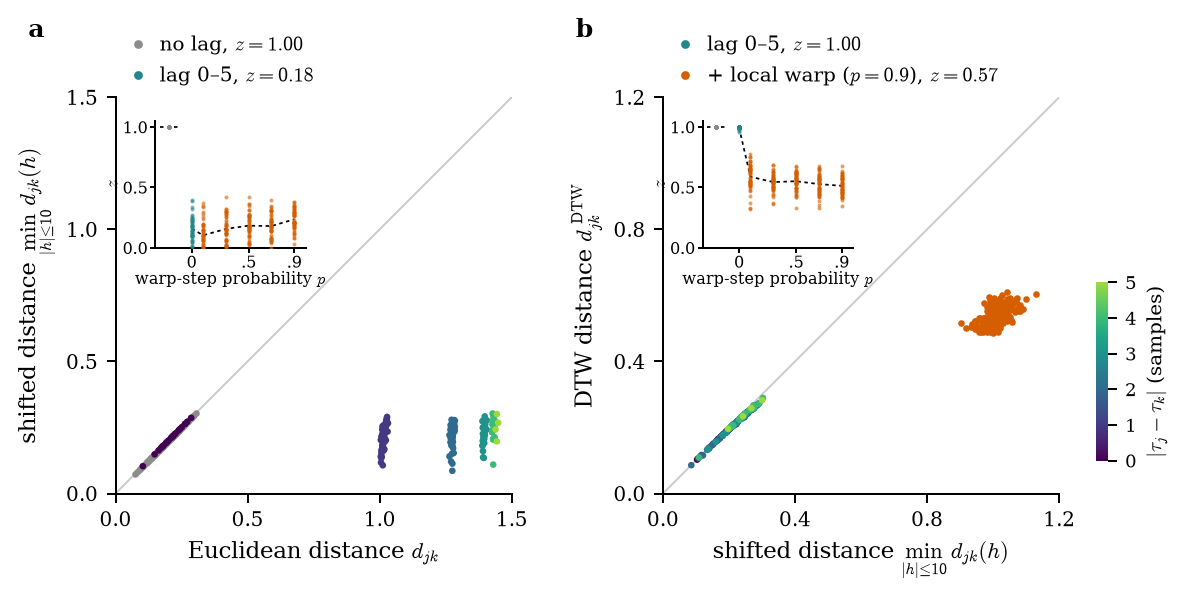

In [2]:
fig = ep.plot_dtw(frame, p_show=P_SHOW)
ep.save(fig, OUT, 'dtw-euclidean_edge-planes')
plt.show()

## Checks

1. Redundancy with the Fig. 1 statistics. On z-scored channels Euclidean distance is exactly $\sqrt{2-2r}$. Shifted distance is compared with $\sqrt{2-2\max_{|h|\le10} r(h)}$; the archive's endpoint-matched shifts differ only at the boundaries.
2. What the distance profiles track. For each recording, correlate each distance profile with pair noise level $s_j^2+s_k^2$, the designed strength axis. Under warping, also correlate it with each pair's relative deformation $\mathrm{SD}_t[h_j(t)-h_k(t)]$, taken from the replayed generating maps. Noise SDs are not stored in the archive, so they are recovered by replaying the generator's draw order; the no-lag control confirms the replay.

In [3]:
checks = ep.dtw_checks(frame)
checks.to_csv(OUT / 'checks_by_recording.csv', index=False)
print(f"max |Euclidean - sqrt(2 - 2r)| over all recordings: {checks.ed_minus_sqrt_2_2r.max():.1e}")
checked = checks.groupby(['max_lag', 'p_step'])[['z_xd_xcorr_distance', 'z_r_xcorr', 'z_ed_noise', 'z_xd_noise', 'z_dtw_noise', 'deform_mean', 'deform_sd_over_pairs', 'z_xd_deform', 'z_dtw_deform']].mean().round(3)
checked

max |Euclidean - sqrt(2 - 2r)| over all recordings: 4.7e-14


z_xd_xcorr_distance  z_r_xcorr  z_ed_noise  z_xd_noise  \
max_lag p_step                                                           
0       0.0                   1.000      1.000       0.981       0.981   
5       0.0                   0.962      0.010       0.022       0.948   
        0.1                   0.990      0.018      -0.012       0.335   
        0.3                   0.996      0.100       0.021       0.220   
        0.5                   0.996      0.131       0.036       0.150   
        0.7                   0.998      0.136       0.036       0.147   
        0.9                   0.998      0.194       0.054       0.144   

                z_dtw_noise  deform_mean  deform_sd_over_pairs  z_xd_deform  \
max_lag p_step                                                                
0       0.0           0.976          NaN                   NaN          NaN   
5       0.0           0.954          NaN                   NaN          NaN   
        0.1           0.707        0.965                 0.040        0.436   
        0.3           0.253        1.466                 0.043        0.277   
        0.5           0.069        1.706                 0.046        0.196   
        0.7          -0.065        1.844                 0.049        0.167   
        0.9          -0.143        1.924                 0.059        0.146   

                z_dtw_deform  
max_lag p_step                
0       0.0              NaN  
5       0.0              NaN  
        0.1            0.200  
        0.3            0.109  
        0.5            0.049  
        0.7            0.018  
        0.9            0.015

In [4]:
def ms(s): return {'mean': round(float(s.mean()), 4), 'sd': round(float(s.std()), 4), 'n': int(len(s))}
out = {'source': 'data/cases/dtw-euclidean-260924 (pyspi r7, archived; not recomputed)', 'p_step_figure': P_SHOW,
       'figure_instance': 0,
       'z': {f'lag{int(l)}|p{p:g}': {k: ms(g[k]) for k in cols} for (l, p), g in frame.groupby(['max_lag', 'p_step'])},
       'max_abs_euclidean_minus_sqrt_2_2r': float(checks.ed_minus_sqrt_2_2r.max()),
       'checks_mean': {f'lag{int(l)}|p{p:g}': row.to_dict() for (l, p), row in checked.iterrows()}}
(OUT / 'summary.json').write_text(json.dumps(out, indent=1) + '\n')
print('wrote', (OUT / 'summary.json').relative_to(ROOT))

wrote results/cases/dtw-euclidean-261020/summary.json


## Interpretation

**{Euclidean, shifted}: fixed lag.** z is 1.000 without lags and 0.16 ± 0.10 with lags of 0–5, and it stays at 0.10–0.24 under warping. On z-scored channels, Euclidean distance is exactly √(2 − 2r) (maximum error 5 × 10⁻¹⁴). Shifted distance tracks √(2 − 2 max cross-correlation) at z = 0.96–1.00. This pair is therefore Fig. 1's {zero-lag r, max cross-correlation} in distance form. Its regime is more extreme: lags span 3.5 mother correlation times (Fig. 1: ≤ 1.6), so zero-lag r ≈ 0.5^|Δτ| and the Euclidean profile becomes a step function of |Δτ| (the columns in panel a). The conditions also differ in zero-lag structure, so this shows lag sensitivity, not aliasing. The effect is strong but duplicates Fig. 1.

**{shifted, DTW}: local versus global alignment.** z is 0.999 without lags and 0.995 ± 0.008 with lags: both distances absorb fixed lags and track channel noise (z ≈ 0.95). Any local warp breaks the agreement: 0.59 ± 0.10 at p = 0.1, then 0.54–0.51 up to p = 0.9. This supports a presence contrast between global shifts and local deformation, not a graded warp amount. The mechanism is only partly identified. Every channel is warped independently with the same p, so relative deformation barely varies across pairs: its mean is 0.97–1.92 samples and its SD across pairs 0.04–0.06. It correlates only 0.15–0.44 with the shifted distance and 0.02–0.20 with DTW. Under warping, the shifted profile loses its noise structure first (0.95 → 0.34 at p = 0.1). DTW follows for p ≥ 0.5 (→ −0.14). The remaining shared variation (z ≈ 0.5) has no identified pair-level source.

**{Euclidean, DTW}.** z is 0.999, then about 0.15 for lag and every warp level. As the union, it is dominated by the lag rung and adds nothing.

**Triplet.** (z_ES, z_SD, z_ED) is (1.00, 1.00, 1.00) with no lag, (0.16, 0.995, 0.15) with lag, and about (0.18, 0.54, 0.15) with lag plus warp. For fixed lags the odd one out names the rung (Euclidean), as in the r–ρ–MI case. With warping nothing agrees, because the lag rung stays broken; unlike r–ρ–MI, the second step does not restore the first pair.

**Continuity with Fig. 1.** Both cases are invariance ladders. The value ladder runs affine ⊂ monotone ⊂ invertible maps of each channel; the time ladder runs no shift ⊂ global shift ⊂ monotone warp. z between adjacent rungs drops when channel pairs differ by a transformation the tolerant statistic absorbs and the restrictive one does not. Fig. 1 is the first time rung with the zero-lag structure held fixed. This case's distinctive content is panel b.

## Flags

- **Redundant SPIs.** Euclidean ≡ √(2 − 2r) exactly on z-scored data, and shifted ≈ √(2 − 2 max cross-correlation), so panel a duplicates Fig. 1. Suggested, not done: use one time ladder across Fig. 1 and this case, either {zero-lag r, max cross-correlation, DTW} or the distance trio, not both. Keep the value ladder {r, ρ, MI} in the r–ρ–MI case. Spearman in Fig. 1 can stay as the cross-ladder control.
- **Homogeneous warp.** Every channel is warped with the same p, so z(shifted, DTW) acts as a presence detector with a plateau. It cannot read heterogeneity of local deformation across pairs, which is what a cross-pair z targets. Warping a subset of channels, or varying p per channel, would make it the analogue of Fig. 1's delay heterogeneity.
- **Extreme lag regime.** With a = 0.5, lags of 0–5 span 3.5 correlation times. A slower mother (Fig. 1 uses a = 0.9) would make the lag rung graded rather than a step.
- **Unexplained level.** Do not interpret the z ≈ 0.5 level under warping; its pair-level source is unknown.
- **Confusing parameter.** p is a path-excursion probability, not the warped fraction. The realised map also has a nonzero mean offset (−0.9 samples at p = 0.9; 261016 viewer).
- **Archive gap.** The lagged-warping archive does not store per-channel noise SDs (filter-roll does); they are recovered here by replaying the RNG. Store them in meta.json.
- **Over-reach.** Shifted versus Euclidean distance is not a delay estimate, z(shifted, DTW) is not a warp amount, and DTW's lower cost does not show recovery of the generating map.
- **Configuration clash.** xpdist uses τ = 30 in Fig. 1 and τ = 10 here, and τ must exceed the lag range. A shared time ladder needs one τ chosen for the longest lag.